# Overview

This will look at the noise on the template (estimate via the 25 phases, take std of mean) and compare it to the sample noise of the halo spectra. I want this to be small.

This will look only at the reduced EFT model, so the EFT model with no $b_{td}$ or $b_{\nabla^2}$.

In [1]:
import sys
sys.path.append('/home/kboone/software/Galaxy_Bias/Bispectrum/Sim_BiasFitting/')

import h5py
import numpy as np
from Fits_Helpers import *
import matplotlib.tri as tri
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline as spline

import matplotlib
matplotlib.style.use('boone')

In [2]:
phases = 25
sim_root = '/mnt/nvme1/kboone/Data/BigFiles/Gala_8/'
model_root = '/mnt/nvme1/kboone/Sims/'
pos_root = '../../Data/Gala_z8_Positions/'
z = 8
rescale = (8+1)/(z+1)

L = 2000
N_grid = 256
kF = 2*np.pi/L
kN = N_grid*np.pi/L
kN_tsc = 2048*np.pi/L
phases = 25
realizations = 25   # Template realizations, files *_v1 ... *_v25

def W(k):
    return (np.sin(np.pi*k/(2*kN_tsc)) / (np.pi*k/(2*kN_tsc)))**3

noises = np.zeros(phases)
for ph in np.arange(phases):
    with h5py.File(pos_root + 'Gala_ph0' + '{:02d}'.format(ph) + '.h5', 'r') as f_:
        noises[ph] = L**3/f_['dataset'].shape[1]
noise = np.mean(noises) # Average noise, use this as the noise in bispectrum.

In [3]:
best_fits = np.load('Fits_z8/Reduced_Best_Fits.npy')
_, _, _, abp, b1, b2, bK2, _, _, _ = np.average(best_fits, axis=0)

# I don't need to account for power spectrum noise or constant bispectrum noise, it'll cancel out.

In [4]:
# Power spectrum: unbinned, up to kN. (kBins/numBins only matter for the binned output, which isn't used here.)
numBins = 12
kBins = np.geomspace(kF, kN, numBins + 1)
kBins = np.maximum(kBins, (np.arange(numBins+1)+0.5)*kF)

P_data = []
for ph in np.arange(phases):
    power_file = sim_root + 'Gala_ph0' + '{:02d}'.format(ph) + '/Gala_256_ps.dat'
    _, k, _, _, _, _ = data_power(power_file, kBins, numBins)
    P_data.append(sims_power(power_file, kBins, numBins, W(k))[0])
P_data = np.array(P_data)
Wk = W(k)
std_P = np.std(P_data, axis=0, ddof=1)
std_P_t = np.std((P_data.T - P_data[:,-1]).T, axis=0, ddof=1) # This doesn't actually matter much.

# Bispectrum
Bs = []
for ph in np.arange(phases):
    bs_file = sim_root + 'Gala_ph0' + '{:02d}'.format(ph) + '/Gala_256_comb.dat'
    B, kB = data_bispec(bs_file, 0.5*kF, 64.5*kF, kN/4, kN)
    Bs.append(B)
Bs = np.array(Bs)
std_B = np.std(Bs, axis=0, ddof=1)

num_ave_B = 100 # Number of high k modes to average to subtract shot noise.

std_B_t = np.std((Bs.T - np.average(Bs[:,-num_ave_B:], axis=1)).T, axis=0, ddof=1)
k1, k2, k3 = kB[:,0], kB[:,1], kB[:,2]
ksum = k1 + k2 + k3
W123 = W(k1)*W(k2)*W(k3)

In [5]:
def load_Ps(root, sym=1):
    P_reals = []
    for v in np.arange(1, 1+realizations):
        power_file = model_root + 'PowerSpectra/' + root + '_ps_v' + str(v) + '.dat'
        P_reals.append(sims_power(power_file, kBins, numBins, W(k), sym_factor=sym)[0])
    return np.array(P_reals)

def load_Bs(root, sym=1):
    B_reals = []
    for v in np.arange(1, 1+realizations):
        bi_file = model_root + 'Bispectra/' + root + '_comb_v' + str(v) + '.dat'
        B_reals.append(sims_bispec(bi_file, kB, sym_factor=sym))
    return np.array(B_reals)

In [6]:
# Now load in the templates.
b1b1s = load_Ps('b1b1') + load_Ps('F2F2') + load_Ps('b1F3', sym=2)
b1b2s = load_Ps('b2F2', sym=2)
b1K2s = load_Ps('b1K2_2', sym=2) + load_Ps('K2F2', sym=2)
b2b2s = load_Ps('b2b2')
K2K2s = load_Ps('K2K2')
b2K2s = load_Ps('b2K2', sym=2)

b1b1b2s = load_Bs('b1b1b2', sym=3)
b1b1b1s = load_Bs('b1b1F2', sym=3)
b1b1K2s = load_Bs('b1b1K2', sym=3)

In [7]:
P_splines = []
for v in np.arange(realizations):
    P_splines.append(spline(k, b1**2*b1b1s[v] + b1*b2*b1b2s[v] + b1*bK2*b1K2s[v] + b2**2*b2b2s[v] + bK2**2*K2K2s[v] + b2*bK2*b2K2s[v], bc_type='natural'))

In [8]:
P_models = []
for v in np.arange(realizations):
    P_models.append(Wk**2 * P_splines[v](k))
P_models = np.array(P_models)
std_P_models = np.std(P_models, axis=0, ddof=1)/np.sqrt(realizations)

In [9]:
B_models = []
for v in np.arange(realizations):
    B_models.append(W123 * (b1**2*b2*b1b1b2s[v] + b1**3*b1b1b1s[v] + b1**2*bK2*b1b1K2s[v] + abp*noise*(P_splines[v](k1) + P_splines[v](k2) + P_splines[v](k3))))
B_models = np.array(B_models)
std_B_models = np.std(B_models, axis=0, ddof=1)
B_ratio = std_B_models / (np.sqrt(realizations)*std_B)
B_t_ratio = std_B_models / (np.sqrt(realizations)*std_B_t)

In [10]:
np.max(std_P_models/std_P)

np.float64(0.03551941366801239)

In [11]:
plt.figure(dpi = 120)
plt.plot(k, std_P_models/std_P)
# plt.plot(k[:-1], std_P_models[:-1]/std_P_t[:-1])
plt.title('Power Spectrum Template Noise', fontsize=24)
plt.xlabel(r'$k$, h/Mpc', fontsize=24)
plt.ylabel(r'$\sigma_\mathrm{template}/\sigma_\mathrm{halo}$', fontsize=24)
plt.grid()
plt.savefig('v2_Plots/p_noise.pdf', bbox_inches='tight', format='pdf')
plt.close()
# plt.show()

In [12]:
circs = np.arange(33.5*kF, 127.5*kF, 2*kF)
circ_ind = 29

circ = circs[circ_ind]
plot_inds = np.where(np.abs(ksum - circ) < kF)[0]
ks_tri = tri.Triangulation(k2[plot_inds], k3[plot_inds])
circ_title = ', Circumference = ' + str(round(circ, 3)) + ' h/Mpc'

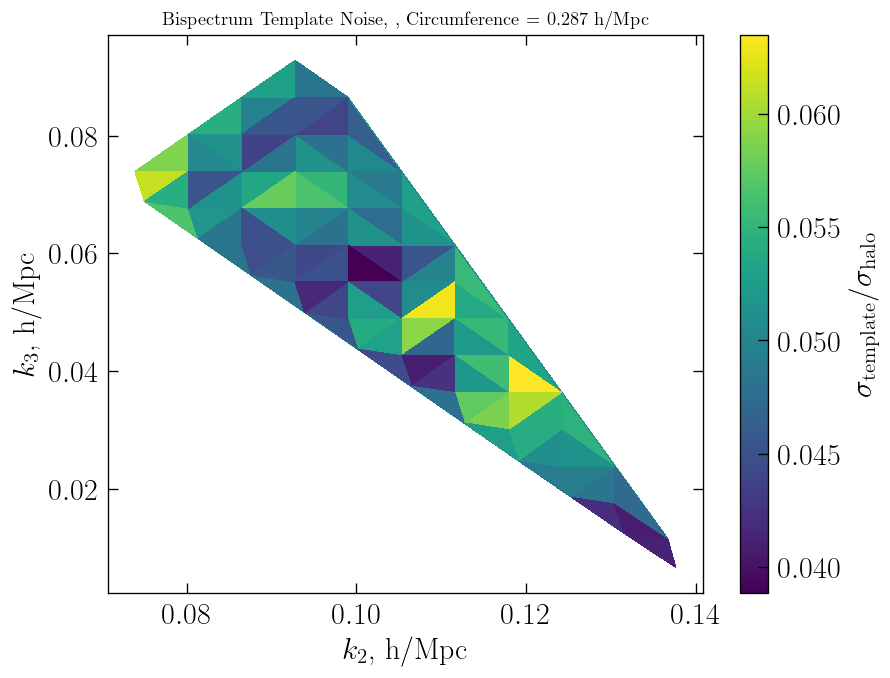

In [13]:
plt.figure(dpi=120)
plt.tripcolor(ks_tri, B_ratio[plot_inds], shading='flat')
plt.colorbar(label=r'$\sigma_\mathrm{template} / \sigma_\mathrm{halo}$')
plt.xlabel(r'$k_2$, h/Mpc')
plt.ylabel(r'$k_3$, h/Mpc')
plt.title('Bispectrum Template Noise, ' + circ_title, fontsize=11)
plt.show()

In [14]:
np.sum(B_t_ratio>0.1)

np.int64(19)

In [15]:
np.max(B_t_ratio)

np.float64(0.15135519248662596)

In [16]:
len(B_ratio)

2389

In [17]:
plt.figure(dpi = 120)
plt.hist(B_ratio, bins=np.linspace(0, 0.2, 21))
plt.yscale('log')
plt.title('Bispectrum Template Noise', fontsize=24)
plt.xlabel(r'$\sigma_\mathrm{template}/\sigma_\mathrm{halo}$', fontsize=24)
plt.ylabel('Number of Triangles', fontsize=24)
plt.grid()
plt.savefig('v2_Plots/b_noise.pdf', bbox_inches='tight', format='pdf')
plt.close()
# plt.show()

In [18]:
# plt.figure(dpi = 120)
# plt.hist(B_t_ratio, bins=np.linspace(0, 0.2, 21))
# plt.yscale('log')
# plt.grid()
# plt.show()